# The NEOARM model

This notebook builds the NEOARM column as a list of TemGym components and traces the beam from the
source to the SightX. The console's DAC values set the lenses and deflectors. The output is where the
beam lands on the SightX and how large it is, in pixels.

**Units.** Along the axis, all lengths are in units of L, the distance from the specimen to the SightX.
The specimen is at 0 and the SightX is at 1. Across the axis, positions are in metres, so a slope is in
metres per L. The width of the SightX, 12 cm, converts metres to pixels (requirement M6).

**The drawing.** JEOL's column drawing gives the positions of the condenser parts. Its specimen-to-screen
distance, 0.719 m, converts the millimetres of the start values to L. This assumes that the screen of the
drawing is at the SightX.

**Two lists.** The components that change hold the console's DAC values (M1). The static components
keep one stated value each (M2, M9). A static component becomes a changing one when its entry moves from
one list to the other (example E12).

**The fits.** The lenses after the specimen come from `fit_projector_lenses.py`, a fit to lens changes
recorded on the real NEOARM. The console's labels set one mean scale for MAG and one for DIFF in that
fit. The condenser comes from `fit_condenser.py`, a fit to recorded beam sizes and parallel settings.
The deflector strengths are start values until a fit to recorded deflector kicks gives them.

In [1]:
import dataclasses
import json
from pathlib import Path

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

from temgym_core.components import Deflector, Lens, Plane, PolePieceLens
from temgym_core.plotting import legacy_beam_plot_params, plot_model
from temgym_core.ray import Ray
from temgym_core.run import position_and_angle_response, run_to_end

jax.config.update("jax_enable_x64", True)

# The figures folder holds only generated images, so git does not keep it.
HERE = Path.cwd()
(HERE / "figures").mkdir(exist_ok=True)
VOLTAGE = 200e3
# The SightX is 12 cm wide, with 1916 pixels. PyJEM reads the frames at binning 4.
PIXEL_M = 0.12 / 1916 * 4
console = json.loads((HERE.parent / "microscope_inversion/recordings/2026-11-17/console_tables.json").read_text())
projector = json.loads((HERE / "projector_lenses.json").read_text())
condenser = json.loads((HERE / "condenser.json").read_text())
drawing = json.loads((HERE.parent / "virtual_neoarm/neoarm_column_diagram.json").read_text())["z_m"]
z_drawing = {name: z / drawing["Screen"] for name, z in drawing.items()}
MM = 1e-3 / drawing["Screen"]

## One state of the microscope

The recording of 2026-11-10 set MAG 40k in this way. The projector lenses have the values of the console
row. CL1 is at 31232 (spot 2), CM at 26624 (alpha 1) and CL3 at 35063. In this state the recording measured a beam of 59.8 px
rms on the SightX. The deflector values are those of the console row, the aligned state of the
microscope. A deflector kicks the beam only when its value moves away from them.

In [2]:
row = next(r for r in console["rows"]["MAG"] if r["mag"][2] == "X40k") | dict(CL1=31232, CL3=35063, CM=26624)
MEASURED_SIZE_PX = 59.76
aligned = {name: np.asarray(row[name], float) for name in ("SpotA", "CLA1", "CLA2")}
print({name: row[name] for name in ("CL1", "CL3", "CM", "IL1", "IL2", "IL3", "PL1", "SpotA", "CLA1", "CLA2")})

{'CL1': 31232, 'CL3': 35063, 'CM': 26624, 'IL1': 41782, 'IL2': 24862, 'IL3': 35544, 'PL1': 64000, 'SpotA': [23422, 43000], 'CLA1': [11096, 32149], 'CLA2': [38284, 44321]}


## The components that change

Each lens is a `PolePieceLens`: Lenz's field of two iron pole pieces, set by the gap and the bore radius
(M10). The coil current is in proportion to the DAC value, with zero current at DAC 0. The image rotation
gives the ampere-turns per DAC unit of each projector lens, but it does not give that zero, which is an
assumption.

`fit_projector_lenses.py` measured the ampere-turns per DAC unit of the projector lenses and fitted their
positions, gaps and bores. The condenser lenses have no rotation measurement. They use the mean of the
projector values, with the sign of PL1. `fit_condenser.py` fitted their gaps and bores. The deflector
strength, 3e-7 rad per DAC unit, is a start value.

The positions of SpotA, CLA1 and CLA2 are not on the drawing. SpotA is between CL1 and CL3. CLA1 and CLA2
are just below the condenser aperture, which the drawing puts at -0.586 L. These three positions are
choices.

In [3]:
KICK_PER_DAC = 3e-7 * drawing["Screen"]       # metres per L per DAC unit
SPOTA_Z, CLA1_Z, CLA2_Z = -0.66, -0.5786, -0.5623

changing = {
    "CL1": PolePieceLens(z=z_drawing["CL1"], turns=1.0, current=condenser["ampere_turns_per_dac"] * row["CL1"],
                         gap=condenser["pole_gap"]["CL1"], bore_radius=condenser["bore_radius"]["CL1"]),
    "SpotA": Deflector(z=SPOTA_Z, def_x=KICK_PER_DAC * (row["SpotA"][0] - aligned["SpotA"][0]),
                       def_y=KICK_PER_DAC * (row["SpotA"][1] - aligned["SpotA"][1])),
    # On the drawing, CL3 sits where the label says CL2.
    "CL3": PolePieceLens(z=z_drawing["CL2"], turns=1.0, current=condenser["ampere_turns_per_dac"] * row["CL3"],
                         gap=condenser["pole_gap"]["CL3"], bore_radius=condenser["bore_radius"]["CL3"]),
    "CLA1": Deflector(z=CLA1_Z, def_x=KICK_PER_DAC * (row["CLA1"][0] - aligned["CLA1"][0]),
                      def_y=KICK_PER_DAC * (row["CLA1"][1] - aligned["CLA1"][1])),
    "CLA2": Deflector(z=CLA2_Z, def_x=KICK_PER_DAC * (row["CLA2"][0] - aligned["CLA2"][0]),
                      def_y=KICK_PER_DAC * (row["CLA2"][1] - aligned["CLA2"][1])),
}
for name in ("IL1", "IL2", "IL3", "PL1"):
    changing[name] = PolePieceLens(z=projector["lens_z"][name], turns=1.0,
                                   current=projector["ampere_turns_per_dac"][name] * row[name],
                                   gap=projector["pole_gap"][name], bore_radius=projector["bore_radius"][name])

## The static components

CM, the objective and the probe corrector do not change in the console rows that this model uses (M2).
CM keeps the value of alpha 1, with the gap and bore that `fit_condenser.py` fitted. The objective's field before the
specimen is the mirror image of the fitted field after it, which is an assumption. The corrector acts as
a relay with a magnification of -1, made of two thin lenses. It inverts the beam and does not focus it.

In [4]:
corrector_top, corrector_bottom = z_drawing["Corrector Top"], z_drawing["Corrector Bottom"]
relay = (corrector_bottom - corrector_top) / 4
static = {
    "corrector top": Lens(z=corrector_top + relay, focal_length=relay),
    "corrector bottom": Lens(z=corrector_bottom - relay, focal_length=relay),
    "CM": PolePieceLens(z=z_drawing["CLMini"], turns=1.0, current=condenser["ampere_turns_per_dac"] * row["CM"],
                        gap=condenser["pole_gap"]["CM"], bore_radius=condenser["bore_radius"]["CM"]),
    "objective before": Lens(z=-projector["objective_z"], focal_length=projector["objective_f"]),
    "objective after": Lens(z=projector["objective_z"], focal_length=projector["objective_f"]),
}
planes = {"specimen": Plane(z=0.0), "SightX": Plane(z=1.0)}

parts = changing | static | planes
names = sorted(parts, key=lambda name: float(parts[name].z))
column = [parts[name] for name in names]
for name in names:
    print(f"{name:17s} z = {float(parts[name].z):+.4f} L")

CL1               z = -0.7101 L
SpotA             z = -0.6600 L
CL3               z = -0.5971 L
CLA1              z = -0.5786 L
CLA2              z = -0.5623 L
corrector top     z = -0.4645 L
corrector bottom  z = -0.2920 L
CM                z = -0.1333 L
objective before  z = -0.0029 L
specimen          z = +0.0000 L
objective after   z = +0.0029 L
IL1               z = +0.2730 L
IL2               z = +0.3931 L
IL3               z = +0.4803 L
PL1               z = +0.5536 L
SightX            z = +1.0000 L


## MAG and DIFF against the console's labels

The part of the column after the specimen gives the magnification from the specimen to the SightX in MAG,
and the camera length in DIFF. Each console row sets the four projector lenses. The plots divide the
model's value by the console's label. They show every row from MAG 8k to 500k and from DIFF 8 cm to 2 m. A flat
line at 1 shows that the lenses follow the console's curve. The fit used the labels for the mean of each
curve only, so the shape of each curve is a test of the lens model. The nominal magnification is the
first scale on the specimen (M7). The camera lengths use the drawing's L.

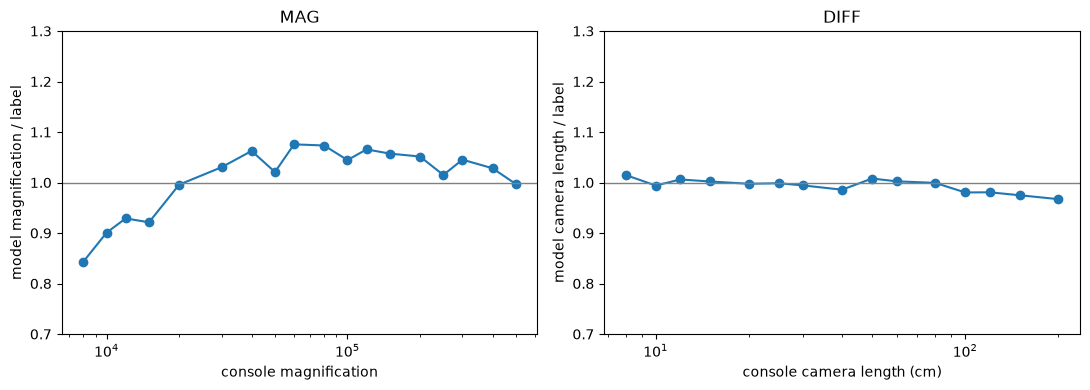

In [5]:
mag_rows = [r for r in console["rows"]["MAG"] if 8000 <= r["mag"][0] <= 500000 and r["mag"][2] != "X25k"]
diff_rows = [r for r in console["rows"]["DIFF"]
             if r["mag"][1] == "mm" and r["OLf"] > 0 and 80 <= r["mag"][0] <= 2000]
projector_names = ("IL1", "IL2", "IL3", "PL1")
after_specimen = names[names.index("specimen"):]
mag_over_label, diff_over_label = [], []
for console_row in mag_rows + diff_rows:
    row_column = [dataclasses.replace(parts[name], current=projector["ampere_turns_per_dac"][name] * console_row[name])
                  if name in projector_names else parts[name] for name in after_specimen]
    a, b = position_and_angle_response(row_column, voltage=VOLTAGE)
    if console_row in mag_rows:
        mag_over_label.append(abs(complex(a)) / console_row["mag"][0])
    else:
        diff_over_label.append(abs(complex(b)) * drawing["Screen"] / (console_row["mag"][0] / 1000))

fig, (ax_mag, ax_diff) = plt.subplots(1, 2, figsize=(11, 4))
ax_mag.semilogx([r["mag"][0] for r in mag_rows], mag_over_label, "o-")
ax_mag.set(title="MAG", xlabel="console magnification", ylabel="model magnification / label")
ax_diff.semilogx([r["mag"][0] / 10 for r in diff_rows], diff_over_label, "o-")
ax_diff.set(title="DIFF", xlabel="console camera length (cm)", ylabel="model camera length / label")
for ax in (ax_mag, ax_diff):
    ax.axhline(1.0, color="grey", linewidth=1)
    ax.set_ylim(0.7, 1.3)
fig.tight_layout()
fig.savefig(HERE / "figures/neoarm_mag_diff_against_labels.png", dpi=110)

From MAG 20k to 500k, the magnification is within 8 % of the label. Every camera length is
within 4 %. MAG 8k to 15k comes out 7 % to 16 % lower. These rows use other lens values, with IL1 from
27,000 to 34,000 and PL1 below 64,000. The model does not yet explain the difference.

## The beam on the SightX

Three rays leave the source, 0.942 L above the specimen on the drawing. The first is the centre of the
beam. The second starts one source size to the side, and the third leaves at one spread of angles. Where
they land on the SightX gives the centre and the rms size of the beam. The source size and the spread
come from `fit_condenser.py`. The recordings do not determine the source size, and the fit drives it to
zero. So the second ray starts on the axis, and the spread of angles alone gives the size.

In [6]:
SOURCE_SIZE_M, SOURCE_SPREAD = condenser["source_size"], condenser["source_spread"]
rays = Ray(x=jnp.array([0.0, SOURCE_SIZE_M, 0.0]), y=jnp.zeros(3),
           dx=jnp.array([0.0, 0.0, SOURCE_SPREAD]), dy=jnp.zeros(3),
           z=jnp.full(3, z_drawing["Source"]), pathlength=jnp.zeros(3), voltage=jnp.full(3, VOLTAGE))
on_camera = run_to_end(rays, column)
xy_px = np.stack([on_camera.x, on_camera.y], axis=1) / PIXEL_M
size_px = np.sqrt(np.sum((xy_px[1:] - xy_px[0]) ** 2))
print(f"MAG 40k: beam centre at ({xy_px[0, 0]:.1f}, {xy_px[0, 1]:.1f}) px, rms size {size_px:.1f} px, "
      f"measured {MEASURED_SIZE_PX} px")

MAG 40k: beam centre at (0.0, 0.0) px, rms size 60.8 px, measured 59.76 px


## The condenser focus at each spot size (example E13)

At alpha 1 the console gives a CL3 value for each spot size. The model's beam goes through its smallest
size at one CL3 value, where the condenser focuses the beam on the specimen. Example E13 asks for that
value within 2500 units of the console's value at each spot. It also asks for both values to fall from
spot 0 to spot 4.
None of the console's spot values went into the fit.

In [7]:
def beam_size_m(cl1, cl3):
    """Return the rms size of the beam on the SightX, in metres, for the DAC values of CL1 and CL3."""
    turns = condenser["ampere_turns_per_dac"]
    lenses = parts | {"CL1": dataclasses.replace(parts["CL1"], current=turns * cl1),
                      "CL3": dataclasses.replace(parts["CL3"], current=turns * cl3)}
    out = run_to_end(rays, [lenses[name] for name in names])
    return jnp.sqrt(jnp.sum((out.x[1:] - out.x[0]) ** 2 + (out.y[1:] - out.y[0]) ** 2))


spot_rows = [r for r in console["spot_alpha"] if r["alpha"] == 1]
cl3_scan = jnp.arange(25000.0, 45001.0, 50.0)
focus_cl3 = []
for spot_row in spot_rows:
    sizes = jax.vmap(lambda cl3: beam_size_m(spot_row["CL1"], cl3))(cl3_scan)
    focus = float(cl3_scan[int(jnp.argmin(sizes))])
    focus_cl3.append(focus)
    print(f"spot {spot_row['spot']}: console CL3 {spot_row['CL3']}, model focus at {focus:.0f}, "
          f"difference {focus - spot_row['CL3']:+.0f}")

# The limits of example E13.
assert all(abs(focus - r["CL3"]) <= 2500 for focus, r in zip(focus_cl3, spot_rows))
assert np.all(np.diff(focus_cl3) < 0) and np.all(np.diff([r["CL3"] for r in spot_rows]) < 0)
print("E13 passes")

spot 0: console CL3 37876, model focus at 38400, difference +524


spot 1: console CL3 35111, model focus at 35050, difference -61


spot 2: console CL3 33493, model focus at 33350, difference -143


spot 3: console CL3 32453, model focus at 32350, difference -103


spot 4: console CL3 31733, model focus at 31650, difference -83
E13 passes


## The column

TemGym's legacy plot draws the column with a fan of rays from the middle of the source. The horizontal
axis is the distance from the axis in a frame that turns with the beam. In this frame, the image rotation
of the lenses does not fold the rays. Components that lie close together share one label.

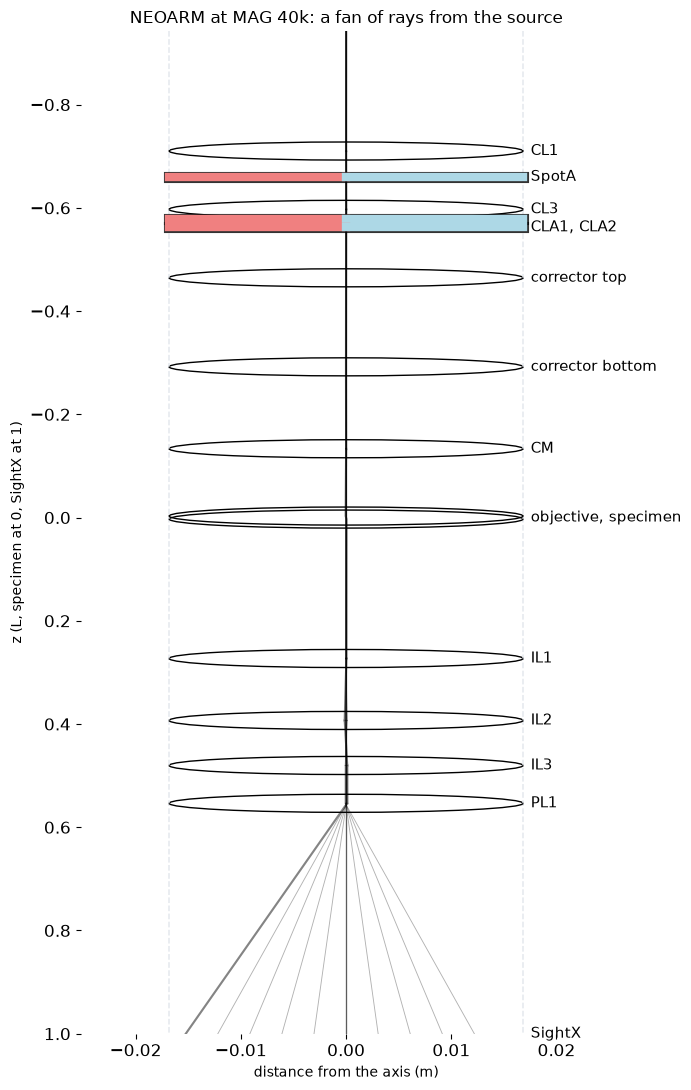

In [8]:
fan_angles = np.linspace(-1, 1, 11) * SOURCE_SPREAD
fan = Ray(x=jnp.zeros(11), y=jnp.zeros(11), dx=jnp.asarray(fan_angles), dy=jnp.zeros(11),
          z=jnp.full(11, z_drawing["Source"]), pathlength=jnp.zeros(11), voltage=jnp.full(11, VOLTAGE))
shared_labels = {"CLA1": "", "CLA2": "CLA1, CLA2", "objective before": "", "objective after": "",
                 "specimen": "objective, specimen"}
labels = [shared_labels.get(name, name) for name in names]
fig, ax = plt.subplots(figsize=(7, 11))
plot_model(column, rays=fan, ax=ax, ray_coordinate="x_rot", component_labels=labels,
           plot_params=legacy_beam_plot_params(label_fontsize=11))
ax.grid(False)
ax.set_yticks(np.arange(-0.8, 1.01, 0.2))
ax.set(title="NEOARM at MAG 40k: a fan of rays from the source",
       xlabel="distance from the axis (m)", ylabel="z (L, specimen at 0, SightX at 1)")
fig.tight_layout()
fig.savefig(HERE / "figures/neoarm_column_mag40k.png", dpi=110)

## Another console row

A new console row changes only the values of the components that change. `dataclasses.replace` gives
each projector lens its new current. DIFF 40 cm is the second row of the recording of 2026-11-10. The
condenser keeps the values of the MAG 40k state. The deflector values of the DIFF row are the same as in
MAG 40k, so the deflectors stay as they are.

In [9]:
diff_row = next(r for r in console["rows"]["DIFF"] if r["mag"][2] == "40cm")
assert all(diff_row[name] == row[name] for name in ("SpotA", "CLA1", "CLA2"))
diff_parts = parts | {name: dataclasses.replace(parts[name], current=projector["ampere_turns_per_dac"][name] * diff_row[name])
                      for name in ("IL1", "IL2", "IL3", "PL1")}
diff_column = [diff_parts[name] for name in names]
a, b = position_and_angle_response(diff_column[names.index("specimen"):], voltage=VOLTAGE)
camera_length_m = abs(complex(b)) * drawing["Screen"]
print(f"DIFF 40 cm: camera length {camera_length_m:.2f} m with the drawing's L, "
      f"{camera_length_m / 0.40:.2f} times the label")
on_camera = run_to_end(rays, diff_column)
xy_px = np.stack([on_camera.x, on_camera.y], axis=1) / PIXEL_M
print(f"DIFF 40 cm: beam centre at ({xy_px[0, 0]:.1f}, {xy_px[0, 1]:.1f}) px, "
      f"rms size {np.sqrt(np.sum((xy_px[1:] - xy_px[0]) ** 2)):.1f} px")

DIFF 40 cm: camera length 0.39 m with the drawing's L, 0.99 times the label


DIFF 40 cm: beam centre at (0.0, 0.0) px, rms size 30.7 px
